# Postperfilado de la base bibliográfica final

Revisión de la base 2024–2025. Cada fila representa la participación de un autor UNAM en un artículo. Un mismo `indice` puede aparecer en varias filas.

In [16]:
import os
import re
import pandas as pd
import matplotlib.pyplot as plt

archivo = "../04_Limpieza/06_Finales/Canonico_FINAL.csv"
carpeta = "../03_perfilado"

df = pd.read_csv(archivo, dtype=str, keep_default_na=False, encoding="utf-8-sig")

# Convertimos celdas vacías o con espacios a NA
df = df.replace(r"^\s*$", pd.NA, regex=True)

print(f"{len(df):,} filas y {len(df.columns)} columnas")
df[["indice", "Titulo", "Año", "Autor_norm", "Area"]].head()

1,151 filas y 14 columnas


,indice,Titulo,Año,Autor_norm,Area
0,1,A comparative study of NeuralODE and Universal...,2024,Raymundo Vazquez Martinez,CC
1,2,A Comparative Study of Numerical Laplace Inver...,2025,Vladimir Martínez Bernardino,CC
2,3,A Greenfield Analysis for Supply Chains Enhanc...,2024,Jose Antonio Marmolejo Saucedo,CC
3,4,A Hierarchical Approach to a Tri-Objective Por...,2024,Carlos Ignacio Hernández Castellanos,CC
4,4,A Hierarchical Approach to a Tri-Objective Por...,2024,Yeudiel Lara Moreno,CC


## 1. Artículos y participaciones

La clave de una participación es `indice` junto con `Autor_norm`. Los nombres de autor se cuentan por coincidencia exacta.

In [17]:
pares = df.dropna(subset=["indice", "Autor_norm"])
repetidas = pares.duplicated(subset=["indice", "Autor_norm"], keep=False)

indices_malos = (~df["indice"].str.fullmatch(r"\d+", na=True)).sum()
varios_autores = df["Autor_norm"].str.contains(";", na=False).sum()

print("Filas del CSV:", len(df))
print("Artículos con indice distinto:", df["indice"].nunique())
print("Participaciones artículo-autor distintas:", len(pares.drop_duplicates(["indice", "Autor_norm"])))
print("Nombres de autor distintos:", df["Autor_norm"].nunique())
print("Filas sin indice o sin autor:", len(df) - len(pares))
print("Filas idénticas adicionales:", df.duplicated().sum())
print("Pares indice-autor repetidos:", len(pares[repetidas].drop_duplicates(["indice", "Autor_norm"])))
print("Filas con indice que no es entero:", indices_malos)
print("Filas con ';' en Autor_norm:", varios_autores)

if repetidas.any():
    display(pares.loc[repetidas, ["indice", "Autor_norm"]].sort_values(["indice", "Autor_norm"]))

Filas del CSV: 1151
Artículos con indice distinto: 519
Participaciones artículo-autor distintas: 1151
Nombres de autor distintos: 628
Filas sin indice o sin autor: 0
Filas idénticas adicionales: 0
Pares indice-autor repetidos: 0
Filas con indice que no es entero: 0
Filas con ';' en Autor_norm: 0


## 2. Consistencia y completitud

Se comparan los datos de todas las filas de un mismo artículo. También se marca una diferencia si una fila tiene un valor y otra lo tiene vacío. Cuando un campo presenta diferencias, su valor queda pendiente en el conteo por artículo.

In [18]:
campos = ["Titulo", "Año", "ISBN", "ISSN", "Doi", "URL", "Area", "SubArea", "Keywords", "Abstract"]

grupos = df.groupby("indice", sort=False)[campos]
diferencias = grupos.nunique(dropna=False) > 1

# Tomamos todas las columnas por artículo; si hubo conflicto en algún campo se deja en NA
articulos = grupos.first()
articulos[diferencias] = pd.NA

print("Artículos con diferencias en sus registros:", diferencias.any(axis=1).sum())

if diferencias.values.any():
    for idx, fila in diferencias.iterrows():
        for col in campos:
            if fila[col]:
                print(f"Diferencia en indice {idx}, campo {col}")

Artículos con diferencias en sus registros: 0


In [19]:
filas_perfil = []

for col in df.columns:
    con_dato = df[col].count()
    vacias = df[col].isna().sum()
    comp_fila = round((con_dato / len(df)) * 100, 2)
    unicos = df[col].nunique()
    
    if col in articulos.columns:
        art_dato = int(articulos[col].count())
        comp_art = round((art_dato / len(articulos)) * 100, 2)
    else:
        art_dato = pd.NA
        comp_art = pd.NA
        
    filas_perfil.append({
        "Columna": col,
        "Filas con dato": con_dato,
        "Filas vacías": vacias,
        "Completitud por fila (%)": comp_fila,
        "Valores distintos por columna": unicos,
        "Artículos con dato consistente": art_dato,
        "Completitud por artículo (%)": comp_art
    })

perfil = pd.DataFrame(filas_perfil).set_index("Columna")
display(perfil.fillna("—"))

,Filas con dato,Filas vacías,Completitud por fila (%),Valores distintos por columna,Artículos con dato consistente,Completitud por artículo (%)
Columna,,,,,,
indice,1151,0,100.00,519,—,—
Titulo,1151,0,100.00,515,519,100.0
Año,1151,0,100.00,2,519,100.0
Autor_norm,1151,0,100.00,628,—,—
Afiliacion1,1151,0,100.00,82,—,—
Afiliacion2,71,1080,6.17,17,—,—
ISBN,400,751,34.75,135,178,34.3
ISSN,1000,151,86.88,267,454,87.48
Doi,1069,82,92.88,494,494,95.18


Un guion indica que el conteo por artículo no aplica al campo. `Afiliacion2` corresponde a una segunda afiliación y `SubArea` es opcional. La ausencia de ISBN o ISSN se interpreta según el tipo de publicación.

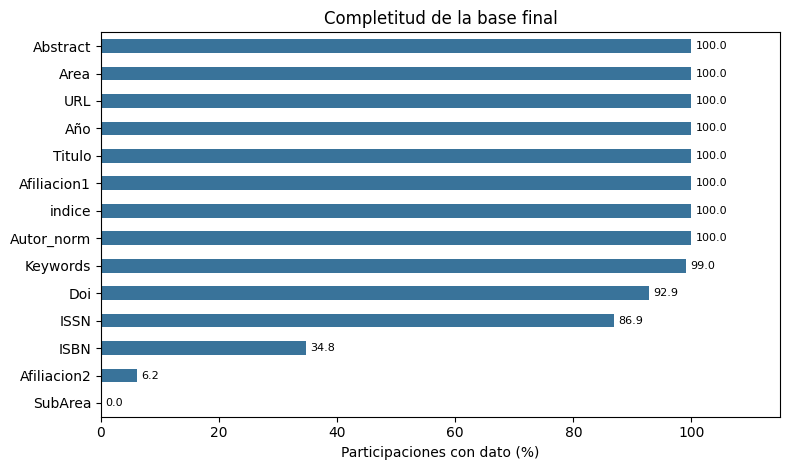

In [20]:
ax = perfil["Completitud por fila (%)"].sort_values().plot(kind="barh", figsize=(8, 4.8), color="#39739a")
ax.bar_label(ax.containers[0], fmt="%.1f", padding=3, fontsize=8)
plt.title("Completitud de la base final")
plt.xlabel("Participaciones con dato (%)")
plt.ylabel("")
plt.xlim(0, 115)
plt.tight_layout()
plt.show()

## 3. Artículos por año y área

Cada artículo se cuenta una vez. La tabla también permite ubicar un año o un área fuera de los valores previstos.

Artículos sin año 2024 o 2025: 0
Artículos fuera de las 6 áreas: 0


Año,2024,2025,Total
Area,,,
CC,56,44,100
IA,73,109,182
ISBD,29,25,54
RS,13,14,27
SIAV,41,59,100
TC,24,32,56
Total,236,283,519


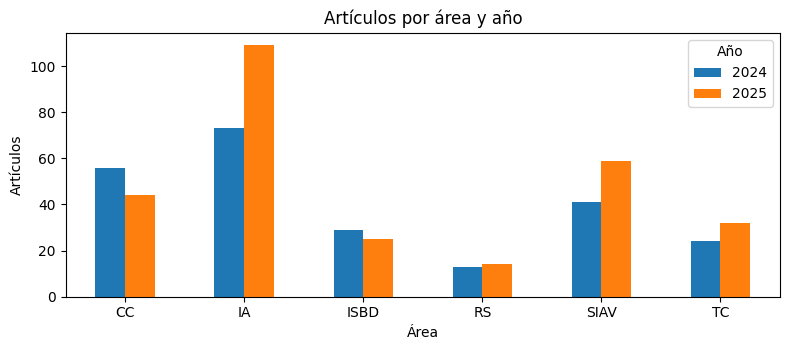

In [21]:
areas = ["ISBD", "CC", "IA", "TC", "SIAV", "RS"]

print("Artículos sin año 2024 o 2025:", (~articulos["Año"].isin(["2024", "2025"])).sum())
print("Artículos fuera de las 6 áreas:", (~articulos["Area"].isin(areas)).sum())

distribucion = pd.crosstab(
    articulos["Area"].fillna("Sin dato"),
    articulos["Año"].fillna("Sin dato"),
    margins=True,
    margins_name="Total"
)
display(distribucion)

# Gráfica sin los totales
distribucion.drop(index="Total", columns="Total").plot(kind="bar", figsize=(8, 3.6), rot=0)
plt.title("Artículos por área y año")
plt.xlabel("Área")
plt.ylabel("Artículos")
plt.tight_layout()
plt.show()

## 4. Autores y afiliaciones

Se cuenta cuántos nombres de autor UNAM tiene cada artículo.

Autores UNAM por artículo:
Autor_norm
1     240
2     112
3      74
4      44
5      26
6      13
7       5
8       3
10      1
12      1
Name: count, dtype: int64


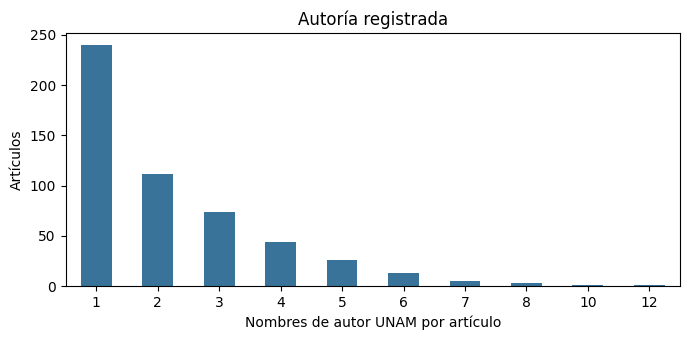

In [22]:
autores_por_art = df.groupby("indice")["Autor_norm"].nunique()
frecuencias = autores_por_art.value_counts().sort_index()

print("Autores UNAM por artículo:")
print(frecuencias)

frecuencias.plot(kind="bar", figsize=(7, 3.5), rot=0, color="#39739a")
plt.title("Autoría registrada")
plt.xlabel("Nombres de autor UNAM por artículo")
plt.ylabel("Artículos")
plt.tight_layout()
plt.show()

In [23]:
todas_afils = pd.concat([df["Afiliacion1"], df["Afiliacion2"]]).dropna()
sin_afil = df["Afiliacion1"].isna() & df["Afiliacion2"].isna()
misma = (df["Afiliacion1"] == df["Afiliacion2"]).fillna(False)

print("Afiliaciónes distintas:", todas_afils.nunique())
print("Autores sin afiliación:", sin_afil.sum())
print("Autores con segunda afiliación:", df["Afiliacion2"].notna().sum())
print("Autores con la misma afiliación en ambos campos:", misma.sum())

if misma.any():
    display(df.loc[misma, ["indice", "Autor_norm", "Afiliacion1", "Afiliacion2"]])

Afiliaciónes distintas: 83
Autores sin afiliación: 0
Autores con segunda afiliación: 71
Autores con la misma afiliación en ambos campos: 0


## 5. Identificadores y posibles coincidencias

Se revisa el formato de los valores presentes. Cuando un artículo tiene varios ISBN o ISSN, se revisa cada uno.

In [24]:
formatos = {
    "Doi": r"10\.[0-9]{4,9}/\S+",
    "URL": r"https?://[^/\s]+(?:/\S*)?",
    "ISBN": r"(?:[0-9]{9}[0-9X]|97[89][0-9]{10})",
    "ISSN": r"[0-9]{4}-[0-9]{3}[0-9X]",
}

for campo, patron in formatos.items():
    errores = []
    for idx, valor in articulos[campo].dropna().items():
        # ISBN e ISSN pueden traer varios separados por ';'
        lista = valor.split(";") if campo in ["ISBN", "ISSN"] else [valor]
        for item in lista:
            item = item.strip()
            if campo == "ISBN":
                item = item.replace("-", "")
            if not re.fullmatch(patron, item):
                errores.append({"indice": idx, "Valor revisado": item})
                
    df_err = pd.DataFrame(errores)
    n_art = df_err["indice"].nunique() if not df_err.empty else 0
    print(f"{campo}: {n_art} artículos con formato por revisar")
    if not df_err.empty:
        display(df_err)

Doi: 0 artículos con formato por revisar
URL: 0 artículos con formato por revisar
ISBN: 0 artículos con formato por revisar
ISSN: 0 artículos con formato por revisar


In [25]:
doi = articulos["Doi"].dropna().str.strip().str.lower()
doi_rep = doi[doi.duplicated(keep=False)]
print("DOI compartidos por distintos índices:", doi_rep.nunique())
if not doi_rep.empty:
    print(doi_rep.sort_values())

con_titulo = articulos.dropna(subset=["Titulo", "Año"])
duplicados = con_titulo.duplicated(subset=["Titulo", "Año"], keep=False)
coincidencias = con_titulo.loc[duplicados, ["Titulo", "Año", "Doi"]].sort_values(["Titulo", "Año"])

n_grupos = len(coincidencias.drop_duplicates(["Titulo", "Año"]))
print("Grupos con el mismo título y año:", n_grupos)
display(coincidencias)

DOI compartidos por distintos índices: 0
Grupos con el mismo título y año: 4


,Titulo,Año,Doi
indice,,,
474,Asynchronous Fault-Tolerant Language Decidabil...,2025,10.1145/3732772.3733514
475,Asynchronous Fault-Tolerant Language Decidabil...,2025,10.48550/arxiv.2502.00191
389,Cloud Detection using Night Sky Background Lig...,2025,10.22323/1.501.0408
390,Cloud Detection using Night Sky Background Lig...,2025,10.48550/arxiv.2509.06343
304,Expanding the Pierre Auger Observatory Open Da...,2025,10.22323/1.501.1251
305,Expanding the Pierre Auger Observatory Open Da...,2025,10.48550/arxiv.2507.08504
200,La Leaderboard: A Large Language Model Leaderb...,2025,10.18653/v1/2025.acl-long.1561
201,La Leaderboard: A Large Language Model Leaderb...,2025,10.48550/arxiv.2507.00999


## 6. Títulos, resúmenes y palabras clave

Se cuenta la longitud de títulos y resúmenes en palabras separadas por espacios. Las palabras clave se separan por punto y coma.

,Palabras del título,Palabras del resumen
Artículos con dato,519.0,519.0
Mínimo,3.0,23.0
Mediana,12.0,150.0
Máximo,36.0,443.0


Resúmenes iguales en más de un índice: 5
Palabras clave distintas (exactas): 5899
Artículos sin palabras clave: 394, 413, 428, 505, 507


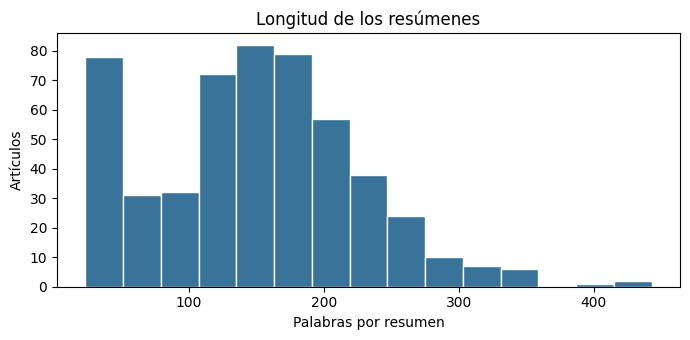

In [26]:
palabras_titulo = articulos["Titulo"].dropna().apply(lambda x: len(x.split()))
palabras_resumen = articulos["Abstract"].dropna().apply(lambda x: len(x.split()))

resumen_long = pd.DataFrame({
    "Palabras del título": [len(palabras_titulo), palabras_titulo.min(), palabras_titulo.median(), palabras_titulo.max()],
    "Palabras del resumen": [len(palabras_resumen), palabras_resumen.min(), palabras_resumen.median(), palabras_resumen.max()],
}, index=["Artículos con dato", "Mínimo", "Mediana", "Máximo"])
display(resumen_long)

# Sacar todas las palabras clave separadas por ';'
keywords = []
for kw in articulos["Keywords"].dropna():
    for palabra in kw.split(";"):
        palabra = palabra.strip()
        if palabra != "":
            keywords.append(palabra)

resumenes = articulos["Abstract"].dropna()
sin_kw = list(articulos.index[articulos["Keywords"].isna()])

print("Resúmenes iguales en más de un índice:", resumenes[resumenes.duplicated()].nunique())
print("Palabras clave distintas (exactas):", len(set(keywords)))
print("Artículos sin palabras clave:", ", ".join(sin_kw) if sin_kw else "Ninguno")

palabras_resumen.plot(kind="hist", bins=15, figsize=(7, 3.5), color="#39739a", edgecolor="white")
plt.title("Longitud de los resúmenes")
plt.xlabel("Palabras por resumen")
plt.ylabel("Artículos")
plt.tight_layout()
plt.show()

## 7. Comparación con el perfilado inicial

Se compara la completitud por fila de los campos comunes entre la unión inicial y la base final.

In [27]:
anterior = carpeta + "/resumen_perfilado.csv"

if os.path.exists(anterior):
    inicial = pd.read_csv(anterior, encoding="utf-8-sig").set_index("Columna")
    
    comparacion = pd.DataFrame({
        "Unión inicial (%)": inicial["Completitud"],
        "Base final (%)": perfil["Completitud por fila (%)"]
    }).dropna()
    
    comparacion["Diferencia (puntos porcentuales)"] = (
        comparacion["Base final (%)"] - comparacion["Unión inicial (%)"]
    )
    
    print(f"Unión inicial: {inicial['Total'].iloc[0]:,} filas. Base final: {len(df):,} participaciones.")
    display(comparacion.round(2))
else:
    print("No se encontró resumen_perfilado.csv. Ejecuta primero el perfilado inicial.")

Unión inicial: 2,582 filas. Base final: 1,151 participaciones.


,Unión inicial (%),Base final (%),Diferencia (puntos porcentuales)
Columna,,,
Abstract,97.48,100.00,2.52
Afiliacion1,92.91,100.00,7.09
Afiliacion2,56.89,6.17,-50.72
Area,100.00,100.00,0.00
Autor_norm,100.00,100.00,0.00
Año,95.16,100.00,4.84
Doi,95.58,92.88,-2.70
ISBN,45.24,34.75,-10.49
ISSN,72.04,86.88,14.84


In [28]:
os.makedirs(carpeta, exist_ok=True)
salida = carpeta + "/resumen_postperfilado.csv"
perfil.to_csv(salida, encoding="utf-8-sig")
print("Resumen guardado en:", salida)

Resumen guardado en: ../03_perfilado/resumen_postperfilado.csv
